# Predicción de devoluciones -- Proyecto de machine learning para reducción de devoluciones en un e-commerce

## Contexto de Negocio.

### Contexto Comercial y Problemática

Actualmente, la infraestructura logística de la empresa está operando por debajo de los estándares esperados, situación que se refleja principalmente en una alta tasa de devoluciones. En un entorno de e-commerce, donde los tiempos de entrega y la confiabilidad del servicio tienen un impacto directo en la experiencia del cliente, estas ineficiencias representan un problema relevante. Los retrasos, los pedidos que no llegan correctamente a destino y las devoluciones no solo afectan la satisfacción y fidelización de los clientes, sino que también generan sobrecostos asociados al transporte, almacenamiento, gestión de devoluciones y reprocesamiento de pedidos, impactando directamente en la rentabilidad de la empresa.

Ante esta situación, resulta necesario comprender cuáles son los principales factores que están afectando el desempeño de la operación logística. Variables como la ubicación de los clientes y depósitos, la categoría de los productos, la prioridad de los pedidos, los tiempos de procesamiento y las características de cada envío pueden permitir identificar patrones que no son evidentes a simple vista. El análisis de estos datos permitirá detectar posibles puntos críticos dentro de la cadena de distribución y determinar en qué etapas se concentran las mayores dificultades. Para ello, utilizaremos un csv que cuenta con 50.000 registros y 30 columnas, cubriendo pedidos registrados entre el 1 de enero y el 31 de diciembre de 2026.

### Objetivo del análisis

El objetivo de este análisis es explorar los datos de envíos recientes para identificar los principales cuellos de botella en la cadena de distribución, analizar su relación con las devoluciones y los retrasos , y detectar oportunidades concretas de mejora. A partir de estos hallazgos, se propondrá un plan de acción basado en datos que permita optimizar los tiempos de entrega, reducir las devoluciones logísticas y mejorar la eficiencia general del sistema de distribución. De esta manera, se busca no solo disminuir los costos operativos, sino también contribuir a una experiencia de compra más confiable y consistente para los clientes.

### Planteo de Hipótesis

H1 (Categoría): Las categorías de mayor rotación/sensibilidad (como Fashion y Electronics) registran una tasa de devolución superior a categorías como Toys.

H2 (Demora): Los envíos con retraso (late_delivery = Yes o mayor delivery_delay_days) concentran una proporción significativamente mayor de solicitudes de devolución.

H3 (Prioridad): A menor prioridad del pedido (Low vs. Urgent), mayor es la tasa de devolución observada.

H4 (Pago): El método de pago muestra diferencias menores en la tasa de devolución en comparación con variables de entrega y calificación.

H5 (Variables críticas): Un subconjunto de variables de entrega, satisfacción y características del pedido concentra el mayor poder predictivo para el modelo.

## Data Adquisition

### Importación de Librerías.

In [1]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

### Recolección de Datos

In [2]:
# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Leer el archivo CSV
ruta = '/content/drive/MyDrive/DATA-SCIENCE/Data-Science-II/Dataset_Envios.csv'
df = pd.read_csv(ruta)

Mounted at /content/drive


## Data Understanding

### Diccionario de datos

1. **order_id** --> Identificador único alfanumérico del pedido (ej. ORD-000001).
2. **order_date** --> Fecha en la que se realizó el pedido (formato AÑO-MES-DÍA).
3. **customer_id** --> Identificador único del comprador.
4. **customer_segment** --> Segmento comercial al que pertenece el cliente (Consumer, Small Business, Premium y Enterprise).
5. **customer_city** --> Ciudad de residencia o destino del cliente.
6. **customer_country** --> País de residencia o destino del cliente.
7. **warehouse_id** --> Identificador único del almacén de origen donde se preparó el pedido.
8. **warehouse_city** --> Ciudad donde está ubicado el almacén de origen.
9. **product_category** --> Categoría principal del producto vendido (ej. Home & Kitchen, Beauty).
10. **product_weight_kg** --> Peso del producto expresado en kilogramos.
11. **order_value_usd** --> Valor total monetario del pedido expresado en dólares estadounidenses (USD).
12. **shipping_method** --> Modalidad de envío seleccionada por el cliente o sistema (ej. Standard, International).
13. **carrier** --> Empresa de logística o transportista encargada de llevar el paquete.
14. **distance_km** --> Distancia total del trayecto de envío en kilómetros.
15. **promised_delivery_days** --> Cantidad de días estimados o prometidos inicialmente para la entrega.
16. **actual_delivery_days** --> Cantidad de días reales que transcurrieron hasta que el paquete fue entregado.
17. **delivery_status** --> Estado del envío al momento del registro (Delivered, In Transit, Delayed, Failed Delivery).
18. **late_delivery** --> Indicador binario (Yes / No) que señala si la entrega superó la fecha prometida.
19. **delivery_delay_days** --> Cantidad de días exactos de retraso. Es 0 si se entregó a tiempo o antes.
20. **shipping_cost_usd** --> Costo logístico del envío expresado en dólares estadounidenses (USD).
21. **package_size** --> Clasificación del tamaño físico del paquete (Small < Medium < Large < Oversized).
22. **payment_method** --> Medio de pago utilizado para abonar el pedido (ej. Digital Wallet, Debit Card).
23. **order_priority** --> Nivel de urgencia o prioridad asignado al procesamiento del pedido (Low < Normal < High < Urgent).
24. **weather_condition** --> Condición climática predominante registrada durante el proceso de envío (ej. Snow, Cloudy).
25. **customer_rating** --> Calificación otorgada por el cliente al servicio o producto, en una escala de 1 a 5.
26. **return_requested** --> Indicador binario (Yes / No) que señala si el cliente solicitó devolver el producto.
27. **return_reason** --> Motivo declarado por el cliente para la devolución (ej. Late Delivery, Product Defect). Es nulo si no hay devolución.
28. **delivery_attempts** --> Número de veces que el transportista intentó entregar el paquete en el domicilio.
29. **warehouse_processing_hours** --> Cantidad de horas netas que tardó el almacén en preparar y despachar el pedido desde su ingreso.
30. **tracking_status** --> Estado de seguimiento público del paquete (Delivered, In Transit, Exception, Out for Delivery).


### Exploración de los datos

In [3]:
# Primero generamos una copia del original para no modificar nada de la información entrante.
df_original = df.copy()

In [4]:
# Vemos el shape de nuestro dataset para entender con lo que estamos trabajando
df.shape
# Vemos que son 50 mil filas y 30 columnas.

(50000, 30)

In [5]:
# Veamos un vistazo a las variables
df.head(5)

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.6,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.9,Delivered


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    50000 non-null  object 
 1   order_date                  50000 non-null  object 
 2   customer_id                 50000 non-null  object 
 3   customer_segment            50000 non-null  object 
 4   customer_city               50000 non-null  object 
 5   customer_country            50000 non-null  object 
 6   warehouse_id                50000 non-null  object 
 7   warehouse_city              50000 non-null  object 
 8   product_category            50000 non-null  object 
 9   product_weight_kg           50000 non-null  float64
 10  order_value_usd             50000 non-null  float64
 11  shipping_method             50000 non-null  object 
 12  carrier                     50000 non-null  object 
 13  distance_km                 500

Con el info podemos ver la cantidad de nulos por columna y el tipo de variable que es cada columna, respetcivamente. Esto es un gran aporte de información para comenzar el Data Wrangling

In [9]:
# Quiero ver como se distribuyen mis datos para tener una base antes de hacer el data Wrangling
df.describe().T
# Reconozco que varias columnas presentan un sesgo negativo. Hay que analizarlo pero nos da un indicio de como se mueven nuestras variables númericas.

,count,mean,std,min,25%,50%,75%,max
product_weight_kg,50000.0,2.255028,3.694952,0.10,0.320,0.93,2.6100,52.19
order_value_usd,50000.0,177.917107,291.600047,10.00,28.720,76.84,173.1625,3530.73
distance_km,50000.0,2496.778802,1774.633152,40.00,1086.775,2182.80,3592.4750,9553.60
promised_delivery_days,50000.0,7.197700,3.680229,0.00,4.000,6.00,11.0000,15.00
actual_delivery_days,50000.0,8.345940,4.644353,0.00,5.000,8.00,12.0000,27.00
delivery_delay_days,50000.0,1.281080,1.679527,0.00,0.000,1.00,2.0000,13.00
shipping_cost_usd,50000.0,120.515538,108.680030,4.05,40.640,82.97,167.4225,500.00
customer_rating,50000.0,3.371840,0.998777,1.00,3.000,3.00,4.0000,5.00
delivery_attempts,50000.0,1.169860,0.390756,1.00,1.000,1.00,1.0000,3.00
warehouse_processing_hours,50000.0,14.412430,9.924904,1.00,6.600,11.90,20.7000,48.00


Se verá de manera más detallada adelante pero quiero mencionar para que no pierda sentido ninguna de las posibles conclusiones sacadas antes de ese punto. La variable objetivo elegida es:
- return_requested --> Indicador binario (Yes / No) que señala si el cliente solicitó devolver el producto.

Se aclara para que no haya confusiones de porque se eliminan ciertan variables del modelo.

In [12]:
# Dejando eso claro, veamos la distribución de nuestra variable objetivo.
proporcion = pd.DataFrame({
    "cantidad": df["return_requested"].value_counts(),
    "porcentaje": (df["return_requested"].value_counts(normalize=True) * 100).round(2)
})
print(proporcion)

                  cantidad  porcentaje
return_requested                      
No                   41375       82.75
Yes                   8625       17.25


Podemos ver que nos encontramos frente a un dataset desbalanceado. Esto es algo bueno (para el negocio, no para nosotros). Ya que tiene sentido que si no se devuelvan tantos pedidos, una proporcion de 8(sin pedir devolución) a 2(con devolución) es una buena proporción. Pero, y puesto en palabras simples, nuestro objetivo es reducir ese 2 a la menor cantidad posible. Optimizando los procesos que sean necesarios para cumplirlo.

## Data Wrangling

### Limpieza del dataset

En esta sección comenzaremos con la limpieza del dataset. Eso incluye tratamiento de nulos, manejo de outliers, tratamiento de duplicados (en nuestro caso no hay ninguno) y como extra: vamos a eliminar variables que obviamente no debería de participar en nuestro modelo (sea por data leakage o por que es irrelevante para nuestro modelo). Cabe aclarar que si hay alguna duda sobre alguna variable, se dejara para un análisis más profundo pero posterior.

In [6]:
# Como ya mencionamos anteriormente con el info podemos ver la cantidad de nulos y los tipos de las columnas de nuestro dataset
df.info()
# Esta información nos permite localizar que la columna return_reason tiene registros nulos.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    50000 non-null  object 
 1   order_date                  50000 non-null  object 
 2   customer_id                 50000 non-null  object 
 3   customer_segment            50000 non-null  object 
 4   customer_city               50000 non-null  object 
 5   customer_country            50000 non-null  object 
 6   warehouse_id                50000 non-null  object 
 7   warehouse_city              50000 non-null  object 
 8   product_category            50000 non-null  object 
 9   product_weight_kg           50000 non-null  float64
 10  order_value_usd             50000 non-null  float64
 11  shipping_method             50000 non-null  object 
 12  carrier                     50000 non-null  object 
 13  distance_km                 500

In [7]:
# Por lo tanto veamos que tan relevantes son esos nulos.
df.isnull().sum()
nulos = (41375/50000) * 100
print(f"return_reason tiene un {round(nulos)}% de nulos")

return_reason tiene un 83% de nulos


Decidí eliminar return_reason no solo porque hay un 83% de nulos, lo que coincide con nuestro porcentaje de pedidos de devolución no hechos. Es decir, hay razón para poder imputarlo con un "Sin Devolución". Pero debido a la naturaleza de nuestra variable objetivo, introducir la razón de una devolución en un modelo para saber si se va a devolver, introduciría la respuesta al modelo, generando data leakage.

In [14]:
# Veamos si existen duplicados
df.duplicated().sum()
# Confirmamos la presencia nula de registros duplicados.

np.int64(0)

Veamos que los id, en nuestro caso, no nos aportan información. Por lo tanto decidí sacarlos del modelo. Lo hago en esta etapa porque se que no hay forma de que brinden una información relevante y reduce los tiempos de análisis y la extensión del dataset

In [15]:
df = df.drop(columns=["return_reason", "order_id", "customer_id", "warehouse_id"])

In [16]:
# Así queda nuestro dataset.
df.head()

,order_date,customer_segment,customer_city,customer_country,warehouse_city,product_category,product_weight_kg,order_value_usd,shipping_method,carrier,...,shipping_cost_usd,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,delivery_attempts,warehouse_processing_hours,tracking_status
0,2026-11-15,Small Business,Tokyo,Japan,Toronto,Home & Kitchen,8.23,10.39,International,EagleCourier,...,133.10,Large,Digital Wallet,Normal,Snow,3,Yes,2,25.1,Delivered
1,2026-04-08,Consumer,Vancouver,Canada,Paris,Beauty,0.10,117.69,Standard,BlueRoute,...,26.95,Small,Debit Card,Normal,Cloudy,5,No,1,25.9,Delivered
2,2026-01-05,Consumer,Houston,United States,London,Home & Kitchen,5.51,335.23,International,SpeedyCargo,...,338.62,Large,Debit Card,Low,Snow,4,Yes,1,31.5,Delivered
3,2026-05-29,Small Business,Delhi,India,Los Angeles,Grocery,3.75,10.57,Standard,ParcelPro,...,270.45,Large,Debit Card,Normal,Snow,3,No,1,12.6,In Transit
4,2026-02-22,Small Business,Nagoya,Japan,Berlin,Beauty,0.10,31.37,Economy,GlobalExpress,...,12.90,Small,Credit Card,Normal,Storm,2,No,1,24.9,Delivered


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_date                  50000 non-null  object 
 1   customer_segment            50000 non-null  object 
 2   customer_city               50000 non-null  object 
 3   customer_country            50000 non-null  object 
 4   warehouse_city              50000 non-null  object 
 5   product_category            50000 non-null  object 
 6   product_weight_kg           50000 non-null  float64
 7   order_value_usd             50000 non-null  float64
 8   shipping_method             50000 non-null  object 
 9   carrier                     50000 non-null  object 
 10  distance_km                 50000 non-null  float64
 11  promised_delivery_days      50000 non-null  int64  
 12  actual_delivery_days        50000 non-null  int64  
 13  delivery_status             500

In [18]:
# Ahora que entendemos un poco más nuestro dataset, pasemos a revisar los outliers.
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

resumen_outliers = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    pct_outliers = (n_outliers / len(df)) * 100
    resumen_outliers.append({
        "columna": col,
        "min": df[col].min(),
        "max": df[col].max(),
        "outliers": n_outliers,
        "%_outliers": round(pct_outliers, 2)
    })
df_outliers = pd.DataFrame(resumen_outliers)
print(df_outliers)

                      columna    min      max  outliers  %_outliers
0           product_weight_kg   0.10    52.19      4712        9.42
1             order_value_usd  10.00  3530.73      5926       11.85
2                 distance_km  40.00  9553.60       656        1.31
3      promised_delivery_days   0.00    15.00         0        0.00
4        actual_delivery_days   0.00    27.00        61        0.12
5         delivery_delay_days   0.00    13.00      1638        3.28
6           shipping_cost_usd   4.05   500.00      2416        4.83
7             customer_rating   1.00     5.00       962        1.92
8           delivery_attempts   1.00     3.00      8201       16.40
9  warehouse_processing_hours   1.00    48.00      1044        2.09


Estos outliers nos permiten comprender un poco más a nuestras variables. Habrían un par de cosas que en un entorno real deberíamos preguntar/investigar, por ejemplo: un order_value de 10 o de 3530 dolares, ¿Es posible?. O que se haya tardado 27 días en entregar un paquete,¿Puede pasar o es un error?, estos ejemplos entre otras cosas. Pero como no tenemos forma de saberlo (aunque podría asumir cosas), en este caso vamos a trabajar con todos ellos ya que un nuestros 2 peores casos son: un 16% (Que es en delivery_attempts, debido a que son números muy bajos y no podríamos imputarlos y que tenga sentido). por otro lado esta el 11% (order_value_usd), en este caso voy a mantener los outliers porque se requeire un análisis más a fondo debido a que los valores podrían ser reales y sin un gráfico apropiado no podemos entender que tan alejados estan de un valor normal, solo tenemos la información del máximo que es 20 veces más caro que la media que vimos en el describe anterior.

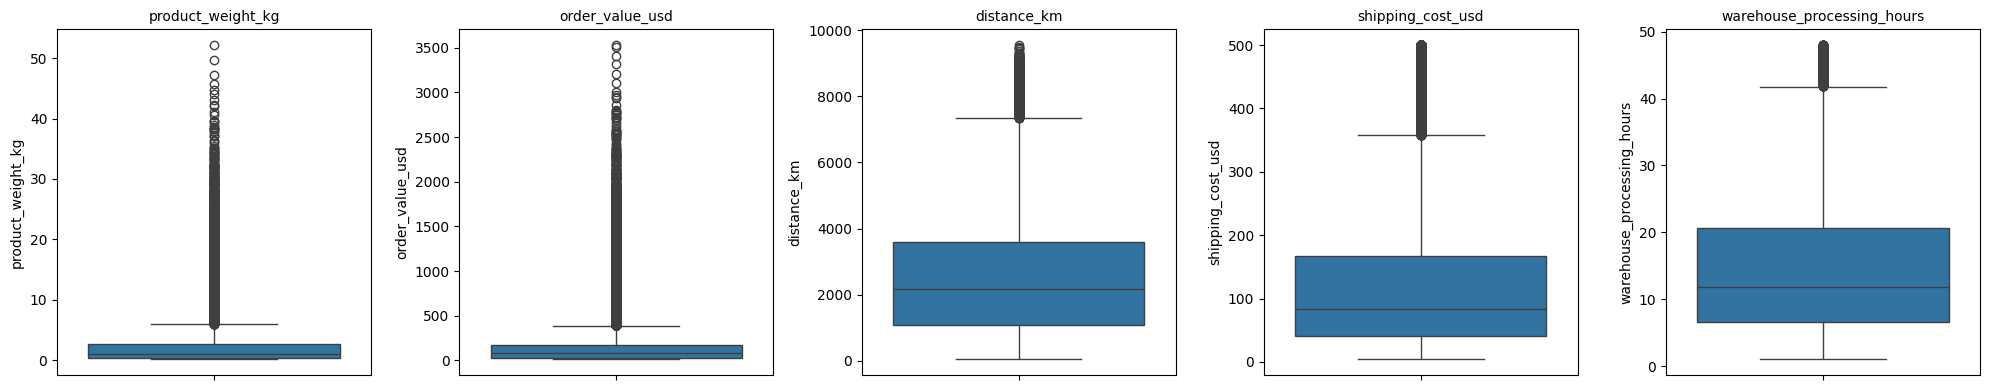

In [21]:
# Nos adelantamos un poco para cerrar el tema de outliers

continuas = [
    "product_weight_kg",
    "order_value_usd",
    "distance_km",
    "shipping_cost_usd",
    "warehouse_processing_hours"
]

fig, axes = plt.subplots(1, len(continuas), figsize=(20, 4))
for ax, col in zip(axes, continuas):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col, fontsize=10)

plt.tight_layout()
plt.show()

Vemos que hay bastantes valores atípicos asi que vamos a desglosarlos uno por uno:
- product_weigth_kg: Me quedo con los outliers (un 10%), pero asumo que hay una relación con otra variable que justifica la diferencia de pesos entre pedidos. Generalmente, pedido más grande > valor > tiempo de entrega (esto es un supuesta a válidar, es una idea para tener en cuenta en el EDA.)
- oreder_value_usd: Me quedo con los outliers, es normal que hayan pedidos fuera de norma, muy porbablemente porque estamos analaizando todos los segementos juntos. Entonces si un segmento hace, generalemente, pedidos más grandes rompe la norma.
- distance_km: Me lo quedo, debido a que existe en la varaible shipping_method, la opción de international. Nos permite entender que los internacionales la mayoría de las veces van a ser mucho más lejos que los no iternacionales.
- shipping_cost: Como ya menciones anteriormente, es muy proable que sean pedidos de un segmento o distancia que generen esta gran diferencia.
- warehouse_processing_hours: Me lo quedo, más que nada porque esos retrasos de más del doble del tiempo, asumo sin ningún tipo de información, que se deben a sucesos en la vida real. Por ejemplo que haya una sobrexigencia para el warehouse o hubo un problema técnico (error de una máquina, etc). Podría crearse con feature engineering una variable que tenga en cuenta el order_date con los momentos donde más se retraso el warehouse y así poder entender/crear una variable que explique momentos de gran exigencia.

In [19]:
# Habiendo resuelto un primer acercamiento de los outliers(habría que hacer el EDA, para comprender mejor), pasemos con la transformación de nuestra variable order_date a fecha.
df["order_date"] = pd.to_datetime(df["order_date"])

# Verificá que haya quedado en datetime64 y que no haya fallos
print(df["order_date"].dtype)
print("Nulos en order_date:", df["order_date"].isna().sum())

datetime64[ns]
Nulos en order_date: 0


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   order_date                  50000 non-null  datetime64[ns]
 1   customer_segment            50000 non-null  object        
 2   customer_city               50000 non-null  object        
 3   customer_country            50000 non-null  object        
 4   warehouse_city              50000 non-null  object        
 5   product_category            50000 non-null  object        
 6   product_weight_kg           50000 non-null  float64       
 7   order_value_usd             50000 non-null  float64       
 8   shipping_method             50000 non-null  object        
 9   carrier                     50000 non-null  object        
 10  distance_km                 50000 non-null  float64       
 11  promised_delivery_days      50000 non-null  int64     